# Comparing Nuclear Data Libraries with Multigroup Cross Sections

This notebook demonstrates `andalus.CrossSectionMG`, which stores multigroup cross sections, $\bar{\nu}$ and the fission spectrum for one or more nuclides. Combined with sensitivity profiles, it gives the first-order effect on $k_{eff}$ of replacing one cross section library with another.

We use the following systems:

* **HMF001:** bare highly enriched uranium sphere (Godiva)
* **HMF002-001** and **HMF002-002:** Topsy tuballoy reflected oralloy assemblies

### 1. Setup and Imports
We import `andalus` for the core logic and `matplotlib` for visualization.

In [1]:
import matplotlib.pyplot as plt

import andalus

### 2. Reading Multigroup Data from ERRORR Files
ERRORR files contain multigroup values processed by NJOY. A snippet of the raw cross section file of U-235 is shown below.

In [3]:
!head -10 "../data/u235.errorr33"

                                                                     1 0  0    0
 9.223500+4 2.330248+2          6          0        -11          09228 1451    1
 0.000000+0 0.000000+0         33          0         34          09228 1451    2
 1.000000-5 1.000000-1 5.400000-1 4.000000+0 8.315290+0 1.370960+19228 1451    3
 2.260330+1 4.016900+1 6.790400+1 9.166090+1 1.486250+2 3.043250+29228 1451    4
 4.539990+2 7.485180+2 1.234100+3 2.034680+3 3.354630+3 5.530840+39228 1451    5
 9.118820+3 1.503440+4 2.478750+4 4.086770+4 6.737950+4 1.110900+59228 1451    6
 1.831560+5 3.019740+5 4.978710+5 8.208500+5 1.353350+6 2.231300+69228 1451    7
 3.678790+6 6.065310+6 1.000000+7 1.964030+7                      9228 1451    8
                                                                  9228 1  099999


The `CrossSectionMG.from_errorr` method uses `sandy` to extract the multigroup values. We pass a dictionary that maps the ERRORR section to its file, the **ZAI** of the nuclide, and optionally the **MT** numbers to keep. The `label` is the name of the library, which becomes the column name.

* **MT 2, 4, 18, 102:** elastic scattering, inelastic scattering, fission and capture, in barns
* **MT 456:** prompt $\bar{\nu}$, dimensionless
* **MT 35018:** prompt fission neutron spectrum chi, as the fraction of fission neutrons born in each group (the groups sum to 1). The MT number is offset by 35000, as in `Covariance`

In [4]:
?andalus.CrossSectionMG

Init signature:
andalus.CrossSectionMG(
    data=None,
    index: 'Axes | None' = None,
    columns: 'Axes | None' = None,
    dtype: 'Dtype | None' = None,
    copy: 'bool | None' = None,
) -> 'None'
Docstring:     
Multigroup nuclear data with a ``(ZAI, MT, E_min_eV, E_max_eV)`` index.

The frame has a single column, named after the library the data comes
from (e.g. ``"jeff40"``). Values are in the natural units of each MT:
barns for cross sections, dimensionless for nubar, and group fractions
(summing to 1) for chi.

Attributes
----------
temperature : float, optional
    Temperature at which the data was generated.

Notes
-----
Sensitivity coefficients are *relative*, :math:`S = (dk/k)/(d\sigma/\sigma)`.
Differences between two libraries must therefore be expressed relative to
the library the sensitivities were computed with, see
:meth:`relative_difference` and :func:`andalus.utils.delta_response`.
File:           c:\users\dhouben\documents\andalus\andalus\cross_section.py
Type:   

In [6]:
files = {
    "errorr31": "../data/u235.errorr31",
    "errorr33": "../data/u235.errorr33",
    "errorr34": "../data/u235.errorr34",
    "errorr35": "../data/u235.errorr35",
}

xs = andalus.CrossSectionMG.from_errorr(files, zai=922350, mts=[2, 4, 18, 102, 456, 34251, 35018], label="base")

### 3. Exploring the Object
The result inherits from `pandas.DataFrame` and has the same index as the sensitivity profiles: `(ZAI, MT, E_min_eV, E_max_eV)`. Using the same energy grid for both is what allows us to combine them bin by bin.

In [7]:
print(xs.head())
print(xs.groupby(level="MT").size())

                                         base
ZAI    MT E_min_eV    E_max_eV               
922350 2  1.00000e-05 1.00000e-01 1.39859e+01
          1.00000e-01 5.40000e-01 1.34700e+01
          5.40000e-01 4.00000e+00 1.21022e+01
          4.00000e+00 8.31529e+00 1.07326e+01
          8.31529e+00 1.37096e+01 1.19508e+01
MT
2        33
4        33
18       33
102      33
456      33
34251    33
35018    33
dtype: int64


Every reaction is defined on the same 33 energy groups. The values are group averages weighted with the NJOY weighting spectrum, so they are not point-wise cross sections.

We plot the fission and capture cross sections of U-235 to see the group structure.

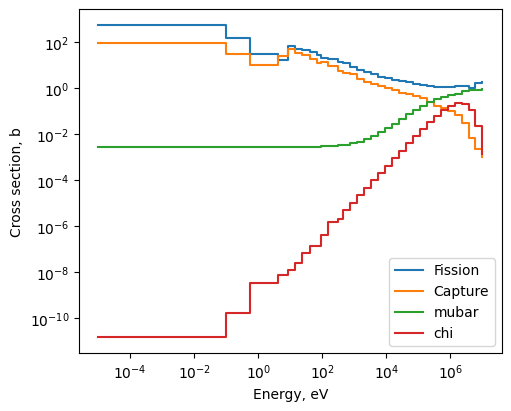

In [8]:
fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
for mt, name in [(18, "Fission"), (102, "Capture"), (34251, "mubar"), (35018, "chi")]:
    group = xs.loc[(922350, mt)]
    ax.step(group.index.get_level_values("E_min_eV"), group["base"], where="post", label=name)
ax.set(xlabel="Energy, eV", ylabel="Cross section, b", xscale="log", yscale="log")
ax.legend()
plt.show()

The fission cross section of U-235 is large at thermal energies and falls to about 1 b in the fast region, where Godiva and Topsy operate. Capture is small compared to fission across the whole range.

### 4. Comparing Two Libraries
Suppose a new library changes some U-235 data. The sensitivity coefficients are *relative*:

$$S_i = \frac{\Delta k / k}{\Delta \sigma_i / \sigma_i}$$

Multiplying $S$ with the absolute difference $\sigma_i - \sigma_i^{ref}$ in barns would mix units. The cross section difference must be divided by the reference value, which is the library that was used to compute the sensitivities:

$$\frac{\Delta k}{k} = \sum_i S_i \, \frac{\sigma_i - \sigma_i^{ref}}{\sigma_i^{ref}}$$

We do not have a second ERRORR set for this example, so we create a hypothetical library in which the U-235 fission cross section is 1% larger and the capture cross section is 5% larger.

In [9]:
new = xs.copy()
mt = new.index.get_level_values("MT")
new.loc[mt == 18, "base"] *= 1.01
new.loc[mt == 102, "base"] *= 1.05
new = andalus.CrossSectionMG(new.rename(columns={"base": "modified"}))

The `relative_difference` method returns the dimensionless difference with respect to the reference. Bins where the reference is zero, for example below a reaction threshold, get a value of zero.

In [10]:
rel = new.relative_difference(xs)
print(rel.groupby(level="MT").mean())

MT
2       0.00000e+00
4       0.00000e+00
18      1.00000e-02
102     5.00000e-02
456     0.00000e+00
34251   0.00000e+00
35018   0.00000e+00
Name: relative_difference, dtype: float64


### 5. Effect on $k_{eff}$
We load the sensitivity profiles of the benchmarks and the application through `AssimilationSuite`. The suite can also hold the cross sections, so we first store them in an HDF5 file, in the same way as for covariances.

In [11]:
xs.to_hdf5("xs_u235.h5")

In [12]:
!cat "config.yaml"

# Global settings for the analysis
covariances:
  file_path: "../data/covariances_test.h5"
  nuclear_data_library: "TEST"
  # Optional: backup covariance file path to use if uncertainties in the primary file are unrealistic
  # backup: "../data/covariances_backup.h5"

# List of benchmarks to be loaded into the BenchmarkSuite
benchmarks:
  - title: "HMF001"
    description: "A bare, highly enriched uranium sphere (GODIVA)."
    m: 1.00000
    dm: 0.00100
    kind: "keff"
    sens0_path: "../data/hmf001.ser_sens0.m"
    results_path: "../data/hmf001.ser_res.m"
    flux_det_name: "flux"
    flux_det_path: "../data/hmf001.ser_det0.m"

  - title: "HMF002-001"
    description: "Topsy 8-inch tuballoy reflected oralloy assemblies (sphere)."
    m: 1.00000
    dm: 0.00300
    kind: "keff"
    sens0_path: "../data/hmf002-001.ser_sens0.m"
    results_path: "../data/hmf002-001.ser_res.m"

applications:
  - title: "HMF002-002"
    description: "Topsy 8-inch tuballoy reflected oralloy assemblies (cy

The `cross_sections` entry points to the HDF5 file we just wrote. The suite exposes the data as `suite.xs` and the sensitivities as `suite.s`. Both use the same index.

In [16]:
suite = andalus.AssimilationSuite.from_yaml("config.yaml")

print(suite.xs.head())
print(suite.s.shape)

Reading ../data/hmf001.ser_res.m
  - done
Reading ../data/hmf001.ser_sens0.m
  - done
Reading ../data/hmf001.ser_det0.m
  - done
Reading ../data/hmf002-001.ser_res.m
  - done
Reading ../data/hmf002-001.ser_sens0.m
  - done
Reading ../data/hmf002-002.ser_res.m
  - done
Reading ../data/hmf002-002.ser_sens0.m
  - done


                                         base
ZAI    MT E_min_eV    E_max_eV               
922350 2  1.00000e-05 1.00000e-01 1.39859e+01
          1.00000e-01 5.40000e-01 1.34700e+01
          5.40000e-01 4.00000e+00 1.21022e+01
          4.00000e+00 8.31529e+00 1.07326e+01
          8.31529e+00 1.37096e+01 1.19508e+01
(693, 3)


The `delta_response` function evaluates the sum above for every case in the suite. Its arguments are the reference library, the sensitivity matrix generated with it, and the library we switch to. The suite offers the same calculation as `suite.delta_response(new)`, with `suite.xs` as the reference.

In [17]:
dk = andalus.delta_response(suite.xs, suite.s, new)
print(dk * 1e5)

HMF001       4.43209e+02
HMF002-001   3.20296e+02
HMF002-002   3.14563e+02
Name: delta_response, dtype: float64


C:\Users\dhouben\AppData\Local\Temp\ipykernel_4328\2569526249.py:1: UserWarning: 261 sensitivity bins with non-zero sensitivity have no cross section data and contribute zero to the response change: ZAI 922380 MT 2 (27 bins, max |S| = 0.0305), ZAI 922380 MT 456 (15 bins, max |S| = 0.0288), ZAI 922380 MT 34251 (27 bins, max |S| = 0.022), ZAI 922380 MT 18 (15 bins, max |S| = 0.0204), ZAI 922380 MT 4 (12 bins, max |S| = 0.0178), ZAI 922380 MT 102 (23 bins, max |S| = 0.00761), ZAI 922380 MT 35018 (21 bins, max |S| = 0.00262), ZAI 922340 MT 456 (15 bins, max |S| = 0.00201), ZAI 922340 MT 18 (15 bins, max |S| = 0.00134), ZAI 922340 MT 34251 (21 bins, max |S| = 0.000633) and 4 more.
  dk = andalus.delta_response(suite.xs, suite.s, new)


The values are relative changes in $k_{eff}$, shown here in pcm. The three systems respond in a similar way, since all are fast uranium systems where U-235 fission dominates. Sensitivity bins without cross section data, such as U-234 and U-238, do not contribute.

### 6. Contribution per Reaction
With `by=["ZAI", "MT"]` the result is split per nuclide and reaction, which shows which change drives the effect.

In [18]:
by_reaction = andalus.delta_response(suite.xs, suite.s, new, by=["ZAI", "MT"])
print(by_reaction * 1e5)

                   HMF001   HMF002-001   HMF002-002
ZAI    MT                                          
922350 2      0.00000e+00  0.00000e+00  0.00000e+00
       4      0.00000e+00  0.00000e+00  0.00000e+00
       18     6.53668e+02  5.73768e+02  5.69795e+02
       102   -2.10459e+02 -2.53472e+02 -2.55233e+02
       456    0.00000e+00  0.00000e+00  0.00000e+00
       34251  0.00000e+00  0.00000e+00  0.00000e+00
       35018  0.00000e+00  0.00000e+00  0.00000e+00


C:\Users\dhouben\AppData\Local\Temp\ipykernel_4328\2691657045.py:1: UserWarning: 261 sensitivity bins with non-zero sensitivity have no cross section data and contribute zero to the response change: ZAI 922380 MT 2 (27 bins, max |S| = 0.0305), ZAI 922380 MT 456 (15 bins, max |S| = 0.0288), ZAI 922380 MT 34251 (27 bins, max |S| = 0.022), ZAI 922380 MT 18 (15 bins, max |S| = 0.0204), ZAI 922380 MT 4 (12 bins, max |S| = 0.0178), ZAI 922380 MT 102 (23 bins, max |S| = 0.00761), ZAI 922380 MT 35018 (21 bins, max |S| = 0.00262), ZAI 922340 MT 456 (15 bins, max |S| = 0.00201), ZAI 922340 MT 18 (15 bins, max |S| = 0.00134), ZAI 922340 MT 34251 (21 bins, max |S| = 0.000633) and 4 more.
  by_reaction = andalus.delta_response(suite.xs, suite.s, new, by=["ZAI", "MT"])


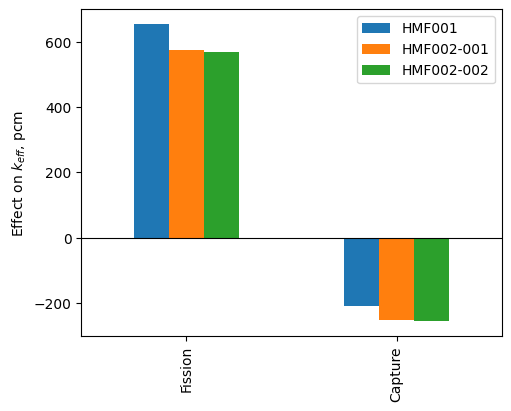

In [19]:
fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
contrib = by_reaction.loc[922350].loc[[18, 102]] * 1e5
contrib.index = ["Fission", "Capture"]
contrib.plot.bar(ax=ax)
ax.set(ylabel="Effect on $k_{eff}$, pcm")
ax.axhline(0, color="black", linewidth=0.8)
plt.show()

A larger fission cross section raises $k_{eff}$, while a larger capture cross section lowers it. The 1% fission change has a larger effect than the 5% capture change, because the fission sensitivity of these systems is more than ten times larger than the capture sensitivity. The first-order estimate is linear in $S$, so it becomes less accurate for large library differences.